In [25]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [26]:
#define state
class BMIState(TypedDict):
    weight:float
    height:float
    bmi:float
    category:str

In [27]:
def calbmi(state:BMIState) ->BMIState:
    weight=state['weight']
    height=state['height']
    bmi=weight/(height**2)
    state['bmi']=round(bmi,2)
    return state

In [32]:
def labelbmi(state:BMIState) ->BMIState:
    bmi=state['bmi']
    if bmi<18.5:
        state['category']="underweight"
    elif bmi<25:
        state['category']="normal"
    elif bmi<30:
        state['category']="overweight"
    else:
        state['category']="obese"
    
    return state

In [29]:
graph=StateGraph(BMIState)
#add nodes in graph
graph.add_node('cal_bmi',calbmi)
graph.add_node('label_bmi',labelbmi)
#add edges in graph
graph.add_edge(START,'cal_bmi')
graph.add_edge('cal_bmi','label_bmi')
graph.add_edge('label_bmi',END)
#compile the graph
workflow=graph.compile()



In [33]:
#execute the graph
outputstate=workflow.invoke({'weight':80, 'height':1.73})
print(outputstate)


{'weight': 80, 'height': 1.73, 'bmi': 26.73}


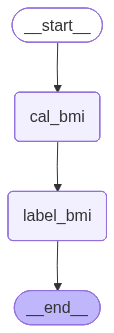

In [12]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())